# DSA4213 Assignment 1, Part II: Embedding variants and ablation

Here I take the 2-layer LSTM from Part I and train it with three different input embeddings. Everything else stays the same: data, vocabulary, architecture, hyperparameters, the 10-epoch budget, the seed, and the starting weights of the non-embedding layers.

| Setting | Input embedding (100-d) | During LM training |
|---|---|---|
| A | random start | trainable (the Part I LSTM, reused) |
| B | my own skip-gram word2vec, trained on the WikiText-2 training split | frozen |
| C | public GloVe 6B 100d | frozen |

## 1. Setup

The data pipeline, model class and training functions below are copied unchanged from Part I, so the vocabulary and batching are exactly the same.

In [ ]:
import os

#Detect Google Colab or localhost
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    SAVE_DIR = "/content/drive/MyDrive/DSA4213 Assignment/results"
else:
    SAVE_DIR = "results"          # a local folder next to the notebook

os.makedirs(SAVE_DIR, exist_ok=True)
# When running locally, reuse the timings/features saved from my Colab (T4) run instead of
# re-measuring them on a slower machine. In Colab everything is measured again.
REUSE_SAVED = not IN_COLAB

print("Running in Colab:", IN_COLAB, "| Saving to:", SAVE_DIR, "| Reusing saved results:", REUSE_SAVED)

Mounted at /content/drive
Running in Colab: True | Saving to: /content/drive/MyDrive/DSA4213 Assignment/results | Reusing saved results: False


In [ ]:
#import, random seed and GPU
%pip install -q datasets gensim

import json
import random, math, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset

SEED = 42 #fixes the randomness so every run gives the same results (for reproducibility)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 53.5 MB/s eta 0:00:00
Using: cuda


In [ ]:
#load wikitext-2
ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

print(ds)

for i in range(1, 8):
    print(repr(ds["train"][i]["text"]))


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
' = Valkyria Chronicles III = \n'
''
' Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside Japan , is a tactical role @-@ playing video game developed by Sega and Media.Vision for the PlayStation Portable . Released in January 2011 in Japan , it is the third game in the Valkyria series . Employing the same fusion of tactical and real @-@ time gameplay as its predecessors , the story runs parallel to the first game and follows the " Nameless " , a penal military unit serving the nation of Gallia during the Second Europan War who perform secret black operations and are pitted against the Imperial unit " Calamaty Raven " 

In [ ]:
#tokenize (split text into words)
def tokenize_split(split):
    tokens = []
    for line in ds[split]["text"]:
        line = line.strip().lower()
        if line == "":
            continue                     # skip empty lines
        tokens.extend(line.split())      # split on whitespace
        tokens.append("<eos>")           # mark the end of each line
    return tokens

train_tokens = tokenize_split("train")
val_tokens   = tokenize_split("validation")
test_tokens  = tokenize_split("test")

print(len(train_tokens), len(val_tokens), len(test_tokens))
print(train_tokens[:30])


2075677 216347 244102
['=', 'valkyria', 'chronicles', 'iii', '=', '<eos>', 'senjō', 'no', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'of', 'the', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'to']


In [ ]:
#build the vocabulary (from train only) and convert words into IDs
MIN_FREQ = 3 #keep words that appear at least 3 times in train
counts = Counter(train_tokens)

itos = ["<unk>", "<eos>"] + sorted(w for w, c in counts.items() if c >= MIN_FREQ and w != "<eos>") #index-to-string, a list to match each word to their position in the list
stoi = {w: i for i, w in enumerate(itos)} #string-to-index, a dictionary built from itos that goes the other way
V = len(itos)
print("Vocab size:", V)

def encode(tokens):
    unk = stoi["<unk>"]
    return [stoi.get(w, unk) for w in tokens]

train_ids = encode(train_tokens)
val_ids   = encode(val_tokens)
test_ids  = encode(test_tokens)

#oov rate = out of vocab rate is the percentage of words in a piece of text that are not in the vocabulary so they are replaced with <unk>
for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]:
    print(f"{name}: {len(ids)} tokens, OOV rate = {ids.count(0)/len(ids):.2%}")


Vocab size: 29572
train: 2075677 tokens, OOV rate = 2.25%
val: 216347 tokens, OOV rate = 4.72%
test: 244102 tokens, OOV rate = 5.62%


In [ ]:
#settings and batchify
BATCH_SIZE = 32       # number of parallel text streams per step
BPTT = 64             # context length: words per chunk
EVAL_BATCH_SIZE = 32

def batchify(ids, bsz):
    """Cut a long list of IDs into bsz equal rows -> tensor of shape (bsz, n)."""
    data = torch.tensor(ids, dtype=torch.long)
    n = len(data) // bsz                 # length of each row
    data = data[: n * bsz]               # drop leftover words that don't fill a full row
    return data.view(bsz, n).to(device)  # reshape long list into a table with 32 rows. row 0 is the 1/32 of the text, row 1 is the next 1/32 and so on. each row is continuous text. then move to GPU

train_data = batchify(train_ids, BATCH_SIZE)
val_data   = batchify(val_ids, EVAL_BATCH_SIZE)
test_data  = batchify(test_ids, EVAL_BATCH_SIZE)

print("train_data shape:", train_data.shape)
print("val_data shape:  ", val_data.shape)
print("test_data shape: ", test_data.shape)


train_data shape: torch.Size([32, 64864])
val_data shape:   torch.Size([32, 6760])
test_data shape:  torch.Size([32, 7628])


In [ ]:
#getting one chunk
def get_batch(data, i):
    """Take columns i..i+BPTT as input, and the same shifted by 1 as target."""
    seq_len = min(BPTT, data.size(1) - 1 - i)   #handles the end of the data, where fewer than 64 words may be left
    x = data[:, i : i + seq_len]                #takes all 32 rows and 64 columns starting at column i
    y = data[:, i + 1 : i + 1 + seq_len]        #same thing as x but shifted one column to the right: the next word at every position
    return x, y

# Check it: decode row 0 of the first chunk
x, y = get_batch(train_data, 0)
print("x shape:", x.shape, " y shape:", y.shape)
print("INPUT :", " ".join(itos[t] for t in x[0, :12].tolist()))
print("TARGET:", " ".join(itos[t] for t in y[0, :12].tolist()))


x shape: torch.Size([32, 64])  y shape: torch.Size([32, 64])
INPUT : = valkyria chronicles iii = <eos> senjō no valkyria 3 : unrecorded
TARGET: valkyria chronicles iii = <eos> senjō no valkyria 3 : unrecorded chronicles


In [ ]:
#settings and the model class
import torch.nn as nn

# ---- Shared hyperparameters for ALL neural models ----
EMB_DIM = 100        # matches GloVe 100d (needed for Part 2)
HIDDEN_DIM = 256
NUM_LAYERS = 2
DROPOUT = 0.3
EPOCHS = 10
LR = 1e-3
CLIP = 1.0

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

class RecurrentLM(nn.Module):
    def __init__(self, vocab_size, cell="lstm", emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM,
                 num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)
        rnn_class = nn.LSTM if cell == "lstm" else nn.RNN
        self.rnn = rnn_class(emb_dim, hidden_dim, num_layers=num_layers,
                             dropout=dropout, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        emb = self.drop(self.embedding(x))   # (B, T)      -> (B, T, 100)
        out, _ = self.rnn(emb)               # (B, T, 100) -> (B, T, 256)
        return self.fc(self.drop(out))       # (B, T, 256) -> (B, T, 29572)


In [ ]:
criterion = nn.CrossEntropyLoss()

def count_params(model):
    return sum(p.numel() for p in model.parameters())

for cell in ["rnn", "lstm"]:
    set_seed()
    m = RecurrentLM(V, cell=cell).to(device)
    x, y = get_batch(train_data, 0)
    logits = m(x)
    loss = criterion(logits.reshape(-1, V), y.reshape(-1))
    print(f"{cell.upper():4s} | params = {count_params(m):,} | output shape = {tuple(logits.shape)} | "
          f"untrained loss = {loss.item():.3f}")

print(f"Expected untrained loss ≈ ln(V) = {math.log(V):.3f}")


RNN  | params = 10,780,436 | output shape = (32, 64, 29572) | untrained loss = 10.309
LSTM | params = 11,450,132 | output shape = (32, 64, 29572) | untrained loss = 10.289
Expected untrained loss ≈ ln(V) = 10.295


In [ ]:
def evaluate(model, data):
    """Average cross-entropy per token over a whole split."""
    model.eval()                                # turn dropout OFF
    total_loss, total_tokens = 0.0, 0
    with torch.no_grad():                       # no learning, just scoring
        for i in range(0, data.size(1) - 1, BPTT):
            x, y = get_batch(data, i)
            logits = model(x)
            loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
            total_loss += loss.item() * y.numel()
            total_tokens += y.numel()
    return total_loss / total_tokens


In [ ]:
def train_model(model, name, epochs=EPOCHS, lr=LR):
    model.to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    history = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best_val = float("inf")
    ckpt_path = os.path.join(SAVE_DIR, f"{name}.pt")
    starts = list(range(0, train_data.size(1) - 1, BPTT))   # start column of every chunk

    for epoch in range(1, epochs + 1):
        model.train()                                        # dropout ON
        random.shuffle(starts)                               # visit chunks in a new order each epoch
        total_loss, total_tokens = 0.0, 0
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()

        for i in starts:
            x, y = get_batch(train_data, i)
            logits = model(x)                                              # 1. predict
            loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))  # 2. measure error
            optimizer.zero_grad()
            loss.backward()                                                # 3. work out how to adjust each weight
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)       # 4. cap overly large adjustments
            optimizer.step()                                               # 5. adjust the weights
            total_loss += loss.item() * y.numel()
            total_tokens += y.numel()

        if device == "cuda": torch.cuda.synchronize()
        epoch_time = time.time() - t0
        train_loss = total_loss / total_tokens
        val_loss = evaluate(model, val_data)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["epoch_time"].append(epoch_time)

        if val_loss < best_val:                              # keep the best version
            best_val = val_loss
            torch.save(model.state_dict(), ckpt_path)

        print(f"{name} | epoch {epoch:2d} | train {train_loss:.3f} (ppl {math.exp(train_loss):6.1f}) "
              f"| val {val_loss:.3f} (ppl {math.exp(val_loss):6.1f}) | {epoch_time:.1f}s")

    model.load_state_dict(torch.load(ckpt_path))             # restore best checkpoint
    with open(os.path.join(SAVE_DIR, f"{name}_history.json"), "w") as f:
        json.dump(history, f)
    return history


In [ ]:
#to prevent Colab disconnecting and losing variables and needing to re-run notebook, use a helper loads a finished model from Drive instead of training it

#train-or-load helper
def train_or_load(model, name):
    ckpt = os.path.join(SAVE_DIR, f"{name}.pt")
    hist = os.path.join(SAVE_DIR, f"{name}_history.json")
    if os.path.exists(ckpt) and os.path.exists(hist):
        model.load_state_dict(torch.load(ckpt, map_location=device))
        model.to(device)
        print(f"Loaded saved {name} (skipping training)")
        with open(hist) as f:
            return json.load(f)
    return train_model(model, name)


In [ ]:
def sample_from_logits(logits, temperature=0.8, top_k=40, greedy=False, gen=None):
    logits = logits.clone()
    logits[stoi["<unk>"]] = -float("inf")          # never generate <unk>
    if greedy:
        return int(torch.argmax(logits))
    vals, idx = torch.topk(logits / temperature, top_k)
    probs = torch.softmax(vals, dim=-1)
    return int(idx[torch.multinomial(probs, 1, generator=gen)])

def generate(next_logits_fn, prompt, n_words=30, greedy=False, seed=SEED):
    gen = torch.Generator().manual_seed(seed)
    ids = encode(prompt.lower().split())
    for _ in range(n_words):
        ids.append(sample_from_logits(next_logits_fn(ids), greedy=greedy, gen=gen))
    return " ".join(itos[i] for i in ids)


In [ ]:
# --- neural models: run the last 64 words, take the scores at the final position ---
@torch.no_grad()
def neural_next_logits(model, ids):
    model.eval()
    x = torch.tensor([ids[-BPTT:]], device=device)
    return model(x)[0, -1].float().cpu()


### Setting A: reusing the Part I LSTM

The Part I LSTM already uses 100-d random, trainable embeddings with the same architecture, data and training procedure, so I reuse it as Setting A. It is loaded from its checkpoint, not retrained.

In [ ]:
with open(os.path.join(SAVE_DIR, "results.json")) as f:
    results = json.load(f)

set_seed()
lstm_model = RecurrentLM(V, cell="lstm")
lstm_hist = train_or_load(lstm_model, "lstm")        # should say "Loaded saved lstm"
print("Setting A test PPL:", math.exp(evaluate(lstm_model, test_data)))


Loaded saved lstm (skipping training)
Setting A test PPL: 178.19008537176987


## 2. Building the two embedding tables

In [ ]:
#train own word2vec
from gensim.models import Word2Vec

def lm_sentences(split):
    """Exactly the tokens the LM sees: lowercased, rare words -> <unk>, <eos> at line end."""
    sents = []
    for line in ds[split]["text"]:
        line = line.strip().lower()
        if line == "":
            continue
        words = [w if w in stoi else "<unk>" for w in line.split()]
        sents.append(words + ["<eos>"])
    return sents

w2v_sents = lm_sentences("train")          # TRAIN split only -> no leakage

w2v_path = os.path.join(SAVE_DIR, "word2vec.model")
if os.path.exists(w2v_path):
    # reuse the word2vec model trained in an earlier run, so Setting B uses exactly the same vectors
    w2v = Word2Vec.load(w2v_path)
    p2_path = os.path.join(SAVE_DIR, "part2_table.csv")
    w2v_time = (float(pd.read_csv(p2_path, index_col=0).loc["B: word2vec, frozen", "Embedding cost"].split("s")[0])
                if os.path.exists(p2_path) else float("nan"))   # training time from the run that created it
    print("Loaded saved word2vec model")
else:
    t0 = time.time()
    w2v = Word2Vec(sentences=w2v_sents, vector_size=EMB_DIM, window=5, sg=1, negative=5,
                   min_count=1, epochs=5, workers=1, seed=SEED)
    w2v_time = time.time() - t0
    w2v.save(w2v_path)

print(f"Word2vec training time: {w2v_time:.1f}s")
print(f"Word2vec vocab: {len(w2v.wv.key_to_index):,} (LM vocab: {V:,})")


Word2vec training time: 64.5s
Word2vec vocab: 29,572 (LM vocab: 29,572)


Notes on word2vec:
* I only train it on the training split, so it never sees the validation or test text.
* Rare words are mapped to `<unk>` first, so word2vec learns exactly the LM's 29,572 words (including `<unk>` and `<eos>`) and covers 100% of the vocabulary.
* `sg=1` is skip-gram, `window=5` looks at 5 words on each side, `negative=5` is negative sampling, and it trains for 5 epochs.
* `workers=1` with a fixed seed makes it reproducible on the same setup. The vectors can still differ very slightly on a different machine or library version (I measured a maximum difference of 0.002 between Colab and my laptop), so the trained model is saved to `word2vec.model` and reused in later runs.
* `w2v_time` (61.9 s on CPU) is the cost of training the embeddings. I report it separately from the LM training time.

In [ ]:
#load GloVe and compare neighbours
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-100")    # GloVe 6B, 100d (~128 MB download)
print(f"GloVe vocab: {len(glove.key_to_index):,}")

for word in ["album", "hurricane", "france", "game"]:
    print(f"\n{word}")
    print("  word2vec:", [w for w, _ in w2v.wv.most_similar(word, topn=6)])
    print("  GloVe:   ", [w for w, _ in glove.most_similar(word, topn=6)])


[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe vocab: 400,000

album
  word2vec: ['songs', 'studio', 'yankovic', 'carey', 'remix', 'soundtrack']
  GloVe:    ['song', 'albums', 'compilation', 'soundtrack', 'ep', 'songs']

hurricane
  word2vec: ['storm', 'cyclone', 'tropical', 'abby', 'depression', 'brenda']
  GloVe:    ['storm', 'katrina', 'typhoon', 'wilma', 'cyclone', 'storms']

france
  word2vec: ['italy', 'germany', 'switzerland', 'russia', 'netherlands', 'spain']
  GloVe:    ['belgium', 'french', 'britain', 'spain', 'paris', 'germany']

game
  word2vec: ['games', 'franchise', 'crush', 'console', 'multiplayer', 'player']
  GloVe:    ['games', 'play', 'season', 'player', 'players', 'match']


* `glove-wiki-gigaword-100` is the GloVe 6B 100d release (Pennington et al., 2014), trained on Wikipedia 2014 and Gigaword 5 newswire (about 6B tokens). I load it with gensim's downloader. It is lowercased, which matches my preprocessing.
* The nearest neighbours show what each embedding has learned. For *game*, my word2vec gives video-game words (*console, multiplayer, franchise*), which fits WikiText-2 having lots of video-game articles, while GloVe gives sports words (*season, match, players*). For *album*, word2vec gives artists that appear in WikiText-2 (*yankovic, carey*) and GloVe gives general synonyms.

In [ ]:
#build the embedding matrices and check coverage
train_id_counts = Counter(train_ids)

def build_matrix(kv, name):
    """Row i = vector for word itos[i]. Words missing from kv get a random vector."""
    rng = np.random.default_rng(SEED)
    known = np.stack([kv[w] for w in itos if w in kv.key_to_index])
    mu, sd = float(known.mean()), float(known.std())

    matrix = np.zeros((V, EMB_DIM), dtype=np.float32)
    missing = []
    for i, w in enumerate(itos):
        if w in kv.key_to_index:
            matrix[i] = kv[w]
        else:
            matrix[i] = rng.normal(mu, sd, EMB_DIM)   # random, same scale as the real vectors
            missing.append(i)

    type_cov = 1 - len(missing) / V
    token_cov = 1 - sum(train_id_counts[i] for i in missing) / len(train_ids)
    print(f"{name}: vocab coverage = {type_cov:.2%} ({V - len(missing):,}/{V:,} words), "
          f"train-token coverage = {token_cov:.2%}")
    top_missing = sorted(missing, key=lambda i: -train_id_counts[i])[:15]
    print("  most frequent missing:", [(itos[i], train_id_counts[i]) for i in top_missing])
    return matrix, missing

w2v_matrix, w2v_missing = build_matrix(w2v.wv, "word2vec")
glove_matrix, glove_missing = build_matrix(glove, "GloVe")


word2vec: vocab coverage = 100.00% (29,572/29,572 words), train-token coverage = 100.00%
  most frequent missing: []
GloVe: vocab coverage = 96.20% (28,447/29,572 words), train-token coverage = 95.11%
  most frequent missing: [('<unk>', 46782), ('<eos>', 23767), ('@-@', 16906), ('@.@', 3194), ('@,@', 2699), ("'t", 592), ('°', 258), ('−', 82), ("'brien", 76), ('×', 75), ("'malley", 54), ('magadheera', 53), ('sorraia', 48), ('degrom', 47), ('₹', 45)]


Notes on the embedding matrices:
* Row i of each matrix is the vector for `itos[i]`, so it lines up with `nn.Embedding`.
* Words missing from the embeddings get a random vector from N(μ, σ), where μ and σ are the mean and standard deviation of the vectors that were found (seed 42), so they are on the same scale. They are frozen like all the other rows.
* I report coverage for both vocabulary words (types) and training tokens.
* word2vec covers 100% because it was trained on this vocabulary. GloVe covers 96.2% of the words and 95.1% of the training tokens. The most common missing ones are `<unk>`, `<eos>` and WikiText's `@-@`, `@.@`, `@,@` tokens, so about 5% of the inputs in Setting C get a fixed random vector. The rest are tokenisation differences (`'t`, `'brien`) and rare names.

## 3. Train the two frozen-embedding LSTMs

In [ ]:
#build and train settings
def make_frozen_lstm(matrix):
    set_seed()                                    # same seed as Setting A -> same LSTM/output init
    m = RecurrentLM(V, cell="lstm")
    m.embedding.weight.data.copy_(torch.from_numpy(matrix))
    m.embedding.weight.requires_grad = False      # freeze the ENTIRE embedding table
    return m

def trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

part2 = {}
for name, matrix in [("lstm_w2v_frozen", w2v_matrix), ("lstm_glove_frozen", glove_matrix)]:
    model = make_frozen_lstm(matrix)
    before = model.embedding.weight.detach().clone()
    print(f"\n{name}: total params = {count_params(model):,}, trainable = {trainable_params(model):,}")
    hist = train_or_load(model, name)
    unchanged = torch.equal(before.to(device), model.embedding.weight.detach())
    print(f"Embedding unchanged after training: {unchanged}")
    part2[name] = {"model": model, "hist": hist}



lstm_w2v_frozen: total params = 11,450,132, trainable = 8,492,932
Loaded saved lstm_w2v_frozen (skipping training)
Embedding unchanged after training: True

lstm_glove_frozen: total params = 11,450,132, trainable = 8,492,932
Loaded saved lstm_glove_frozen (skipping training)
Embedding unchanged after training: True


Notes on the frozen models:
* Calling `set_seed()` before building each model means the LSTM and output layers start from exactly the same weights as Setting A, so only the embedding table is different.
* `requires_grad = False` freezes the whole embedding table, and `train_model` only gives the trainable parameters to the optimizer.
* Trainable parameters: 8.49M (11.45M minus the 2.96M embedding).
* `Embedding unchanged after training: True` confirms the whole table stayed fixed.
* I trained both models in an earlier Colab session, so they are loaded from checkpoints here. The next cell prints their per-epoch logs from the saved history files.

In [ ]:
# Both frozen-embedding LSTMs were trained in an earlier session and are loaded from checkpoints above,
# so their per-epoch training logs are printed here from the saved history files.
for name in ['lstm_w2v_frozen', 'lstm_glove_frozen']:
    with open(os.path.join(SAVE_DIR, f"{name}_history.json")) as f:
        h = json.load(f)
    for epoch, (tl, vl, et) in enumerate(zip(h["train_loss"], h["val_loss"], h["epoch_time"]), 1):
        print(f"{name} | epoch {epoch:2d} | train {tl:.3f} (ppl {math.exp(tl):6.1f}) "
              f"| val {vl:.3f} (ppl {math.exp(vl):6.1f}) | {et:.1f}s")

lstm_w2v_frozen | epoch  1 | train 7.035 (ppl 1135.9) | val 6.394 (ppl  598.4) | 42.6s
lstm_w2v_frozen | epoch  2 | train 6.366 (ppl  581.9) | val 5.885 (ppl  359.7) | 45.0s
lstm_w2v_frozen | epoch  3 | train 5.986 (ppl  397.7) | val 5.630 (ppl  278.5) | 44.2s
lstm_w2v_frozen | epoch  4 | train 5.745 (ppl  312.7) | val 5.475 (ppl  238.6) | 44.6s
lstm_w2v_frozen | epoch  5 | train 5.577 (ppl  264.3) | val 5.376 (ppl  216.1) | 44.5s
lstm_w2v_frozen | epoch  6 | train 5.451 (ppl  233.1) | val 5.308 (ppl  202.0) | 44.5s
lstm_w2v_frozen | epoch  7 | train 5.350 (ppl  210.5) | val 5.263 (ppl  193.1) | 44.5s
lstm_w2v_frozen | epoch  8 | train 5.266 (ppl  193.6) | val 5.223 (ppl  185.4) | 44.5s
lstm_w2v_frozen | epoch  9 | train 5.194 (ppl  180.1) | val 5.194 (ppl  180.2) | 44.4s
lstm_w2v_frozen | epoch 10 | train 5.134 (ppl  169.7) | val 5.177 (ppl  177.2) | 44.6s
lstm_glove_frozen | epoch  1 | train 7.104 (ppl 1217.1) | val 6.583 (ppl  723.0) | 44.1s
lstm_glove_frozen | epoch  2 | train 6.65

## 4. Comparison of the three settings

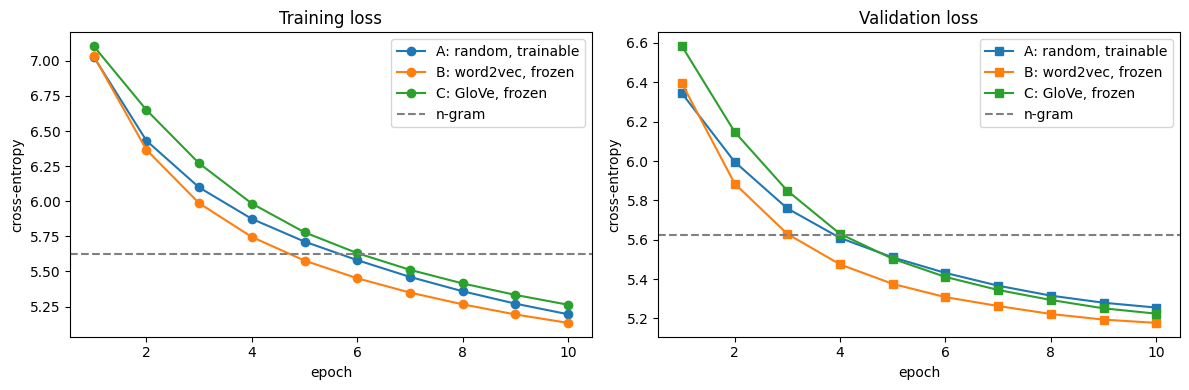

                     Test PPL Trainable params Vocab coverage Val PPL ep1 Val PPL ep5 Val PPL ep10 Epochs val got worse Final train−val gap LM train time (s)                  Embedding cost
A: random, trainable    178.2         11450132            n/a       569.0       247.2        191.6                    0               -0.06             478.3             0 (learned jointly)
B: word2vec, frozen     165.2          8492932         100.0%       598.4       216.1        177.2                    0              -0.044             443.4                64.5s (word2vec)
C: GloVe, frozen        172.9          8492932          96.2%       723.0       245.4        185.8                    0               0.039             445.0  0 (pre-trained, download only)


In [ ]:
#curves and the comparison table
settings = {
    "A: random, trainable":  (lstm_model, lstm_hist),
    "B: word2vec, frozen":   (part2["lstm_w2v_frozen"]["model"], part2["lstm_w2v_frozen"]["hist"]),
    "C: GloVe, frozen":      (part2["lstm_glove_frozen"]["model"], part2["lstm_glove_frozen"]["hist"]),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (_, h) in settings.items():
    ep = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["train_loss"], "o-", label=name)
    axes[1].plot(ep, h["val_loss"], "s-", label=name)
for ax, t in zip(axes, ["Training loss", "Validation loss"]):
    ax.axhline(results["ngram"]["test_ce"], ls="--", c="gray", label="n-gram")
    ax.set_title(t); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "curves_part2.png"), dpi=150)
plt.show()

emb_cost = {"A: random, trainable": "0 (learned jointly)",
            "B: word2vec, frozen": f"{w2v_time:.1f}s (word2vec)",
            "C: GloVe, frozen": "0 (pre-trained, download only)"}
coverage = {"A: random, trainable": "n/a",
            "B: word2vec, frozen": f"{1 - len(w2v_missing)/V:.1%}",
            "C: GloVe, frozen": f"{1 - len(glove_missing)/V:.1%}"}

rows = {}
for name, (model, h) in settings.items():
    test_ce = evaluate(model, test_data)
    vl = h["val_loss"]
    rows[name] = {
        "Test PPL": round(math.exp(test_ce), 1),
        "Trainable params": trainable_params(model),
        "Vocab coverage": coverage[name],
        "Val PPL ep1": round(math.exp(vl[0]), 1),
        "Val PPL ep5": round(math.exp(vl[4]), 1),
        "Val PPL ep10": round(math.exp(vl[-1]), 1),
        "Epochs val got worse": sum(vl[i] > vl[i - 1] for i in range(1, len(vl))),
        "Final train−val gap": round(h["train_loss"][-1] - vl[-1], 3),
        "LM train time (s)": round(sum(h["epoch_time"]), 1),
        "Embedding cost": emb_cost[name],
    }
table2 = pd.DataFrame(rows).T
print(table2.to_string())
table2.to_csv(os.path.join(SAVE_DIR, "part2_table.csv"))

What each column measures:
* Test PPL: prediction quality.
* Val PPL at epochs 1, 5 and 10: how fast each setting converges.
* Epochs val got worse: a simple check of training stability (0 means the validation loss improved every epoch).
* Final train−val gap: negative means the train loss is still above the validation loss, positive suggests the start of overfitting.
* LM train time and embedding cost are reported separately.

## 5. Generated text

I use the same prompts, seeds and decoding settings as in Part I (sampling with temperature 0.8 and top-k 40, and greedy), with 30 tokens each.

In [ ]:
#generated text from all three settings:
prompts = ["the city of", "in 1990 , the", "the game was released", "he was born in", "the album received"]

lines = []
for mode in ["sampling (T=0.8, top-k=40)", "greedy"]:
    lines.append(f"\n########## {mode} ##########")
    for p_i, prompt in enumerate(prompts):
        lines.append(f"\nPROMPT: {prompt}")
        for name, (model, _) in settings.items():
            text = generate(lambda ids, m=model: neural_next_logits(m, ids), prompt,
                            greedy=(mode == "greedy"), seed=SEED + p_i)
            lines.append(f"  [{name:22s}] {text}")

output = "\n".join(lines)
print(output)
with open(os.path.join(SAVE_DIR, "generations_part2.txt"), "w", encoding="utf-8") as f:
    f.write(output)



########## sampling (T=0.8, top-k=40) ##########

PROMPT: the city of
  [A: random, trainable  ] the city of the northern union . the area was demolished . when the company was a new american force , the fort remained in the early 20th century , which was the
  [B: word2vec, frozen   ] the city of the county state to the area . " in may 2003 , the church has no longer than a result of the city of the city , which was the
  [C: GloVe, frozen      ] the city of the song " i 'm to be , and an big in the world ' ' ' ' ' face " . the game was released on july 7 ,

PROMPT: in 1990 , the
  [A: random, trainable  ] in 1990 , the last series of the american theatre of the game of the american song , which aired by the new york 's film . <eos> = = = film = =
  [B: word2vec, frozen   ] in 1990 , the number of the city 's largest schools in the first decades . the original in the national museum , to have been a grade of three @-@ dimensional school in
  [C: GloVe, frozen      ] in 1990 , the gam

Setting A's outputs are exactly the same as the LSTM's in Part I, which confirms the reused model and the decoding settings are identical.

## 6. Interpretation

| Setting | Test PPL | Val PPL ep1 / ep5 / ep10 | Trainable params | Cost (T4) |
|---|---|---|---|---|
| A: random, trainable | 178.2 | 569 / 247 / 192 | 11.45M | 478 s |
| B: word2vec, frozen | **165.2** | 598 / **216** / **177** | 8.49M | 443 s + 62 s word2vec (CPU) |
| C: GloVe, frozen | 172.9 | **723** / 245 / 186 | 8.49M | 445 s |

What I observed:
1. Both frozen settings beat the random trainable embeddings, and my own word2vec beats GloVe, even though GloVe was trained on about 3,000 times more text.
2. Convergence: B is ahead from epoch 2. C starts worst (validation perplexity 723 at epoch 1) but passes A around epoch 5. A starts best but improves more slowly.
3. Stability: all three improve every epoch with smooth curves, so there's no difference here.
4. Overfitting: only C has a slightly positive train−val gap (+0.039).
5. Cost: the frozen models train about 7% faster since there are no embedding gradients. If I add the word2vec time, B's total (505 s) is slightly more than A's (478 s).
6. Coverage: GloVe only misses 3.8% of the words, but these include the most common special tokens, so about 5% of the input positions get meaningless fixed vectors.
7. Generated text: with greedy decoding all three settings collapse into `= = =`, and the sampled text doesn't clearly separate them, so perplexity is the clearer signal.

Possible reasons (not tested):
* Frozen beating trainable: with only 10 epochs, Setting A has to learn the embeddings and the LSTM at the same time, and rare words get very few updates. B and C start with vectors that already capture which words are similar, which gives them a head start. Freezing also removes 2.96M trainable parameters, which might act as regularisation. All the models were still improving at epoch 10, so A might catch up with longer training. My conclusion only holds for this budget.
* word2vec beating GloVe: this looks like domain match mattering more than data size. The nearest neighbours show GloVe using the news/sports meaning of *game*, while WikiText-2 mostly uses the video-game meaning. Frozen GloVe can't adapt to my corpus, and its missing special tokens are some of the most common inputs.
* GloVe's slow start: its vectors come from a different training objective and scale, so the LSTM may need time to adjust to them.

**Overall:** with frozen embeddings, matching the corpus's tokenisation and word usage mattered more than how much data the embeddings were trained on. word2vec trained on 2M in-domain tokens did better than GloVe trained on 6B tokens.